# Lazy prices: do changes in the risk factors of a 10-K predict returns?

**Objective:** Cohen, Malloy and Nguyen (2020, *Journal of Finance*) found that when a company changes the text of its annual report a lot from one year to the next, its stock does worse in the following months, and that the market takes time to notice ("lazy prices"). Here we test the idea with the section **Item 1A. Risk Factors** of the 10-K reports of 92 of the biggest US companies, 2014 to 2026.

1. Text of Item 1A from SEC EDGAR (`download_10k.py`)
2. Four measures of change between the report of one year and the one of the year before: TF-IDF cosine, Jaccard, share of new sentences and cosine of sentence embeddings (multilingual-e5-small)
3. What changed: the topics that appear in the risk factors over time (pandemic, inflation, AI, tariffs...)
4. Returns after the filing: excess return against the S&P 500 at 1 week, 3, 6 and 12 months, by quintile of change and with regressions

**Data:** SEC EDGAR full text of the 10-K reports, Yahoo Finance adjusted prices (`get_prices.py`).

Libraries of the project: `pandas`, `numpy`, `scikit-learn`, `sentence-transformers`, `statsmodels`, `matplotlib` and `seaborn`.

## Part 1. Libraries

In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.feature_extraction.text import TfidfVectorizer
from sentence_transformers import SentenceTransformer

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)

## Part 2. The reports

Each file has the text between the heading "Item 1A. Risk Factors" and the next item. When the section was not found (for example General Electric and Intel put the risk factors inside other sections in some years) the file is almost empty, and we drop the reports with less than 500 words.

In [2]:
rep = pd.read_csv("data/filings.csv")
rep["text"] = [open(f"data/item1a/{f}", encoding="utf-8").read() for f in rep["file"]]
rep["words"] = rep["text"].str.split().str.len()
print("Reports downloaded:", len(rep), "| companies:", rep["ticker"].nunique())
rep = rep[rep["words"] >= 500].copy()
rep["filing_date"] = pd.to_datetime(rep["filing_date"])
rep = rep.sort_values(["ticker", "filing_date"]).reset_index(drop=True)
print("Reports with the section:", len(rep), "| companies:", rep["ticker"].nunique())
rep.groupby(rep["filing_date"].dt.year)["words"].agg(["size", "median"]).rename(columns={"size": "reports", "median": "median_words"})

Reports downloaded: 1168 | companies: 94
Reports with the section: 1087 | companies: 92


,reports,median_words
filing_date,,
2014,80,8411.5
2015,80,7793.0
2016,79,7678.0
2017,82,8098.0
2018,82,8541.0
2019,84,9651.5
2020,85,10777.0
2021,86,12044.0
2022,88,13011.0


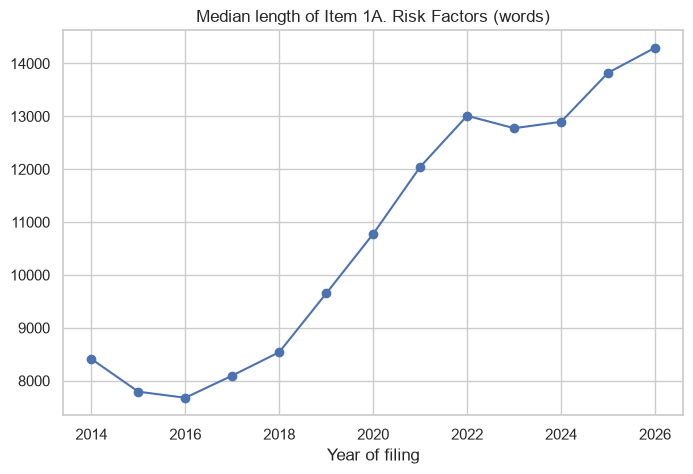

In [3]:
largo = rep.groupby(rep["filing_date"].dt.year)["words"].median()
largo = largo[largo.index <= 2026]
plt.figure(figsize=(8, 5))
largo.plot(marker="o")
plt.title("Median length of Item 1A. Risk Factors (words)")
plt.xlabel("Year of filing")
plt.savefig("figures/length_risk_factors.png", bbox_inches="tight")
plt.show()

The risk factors section grows almost every year, from a median of 8.400 words in 2014 to 14.300 in 2026: companies add risks much more often than they remove them.

## Part 3. Measures of change

For each company we compare every report with the one of the year before (only if they are between 10 and 14 months apart):

- **TF-IDF cosine:** similarity of the word frequencies (words and pairs of words)
- **Jaccard:** words in common over all the words used
- **New sentences:** share of the sentences of this year that do not appear in last year's report (after removing numbers, so a new year or amount does not count as a change)
- **Embeddings:** cosine between the average embedding of the passages of each report, with `intfloat/multilingual-e5-small`. It measures change in meaning more than in words.

In [4]:
def oraciones(t):
    t = re.sub(r"\d[\d,\.]*", "#", t.lower())
    return set(o.strip() for o in re.split(r"(?<=[\.\!\?])\s+", t) if len(o.split()) >= 6)

rep["prev_index"] = np.nan
for tk, g in rep.groupby("ticker"):
    idx = g.index.tolist()
    for a, b in zip(idx[:-1], idx[1:]):
        meses = (rep.loc[b, "filing_date"] - rep.loc[a, "filing_date"]).days / 30.4
        if 10 <= meses <= 14:
            rep.loc[b, "prev_index"] = a
pares = rep.dropna(subset=["prev_index"]).copy()
pares["prev_index"] = pares["prev_index"].astype(int)
print("Pairs of consecutive reports:", len(pares))

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True, stop_words="english")
X = tfidf.fit_transform(rep["text"])
pares["cos_tfidf"] = [X[i].multiply(X[j]).sum() for i, j in zip(pares.index, pares["prev_index"])]

palabras = [set(re.findall(r"[a-z]+", t.lower())) for t in rep["text"]]
pares["jaccard"] = [len(palabras[i] & palabras[j]) / len(palabras[i] | palabras[j]) for i, j in zip(pares.index, pares["prev_index"])]

frases = [oraciones(t) for t in rep["text"]]
pares["new_sentences"] = [len(frases[i] - frases[j]) / len(frases[i]) for i, j in zip(pares.index, pares["prev_index"])]
pares["length_change"] = np.log(pares["words"].values / rep.loc[pares["prev_index"], "words"].values)

Pairs of consecutive reports: 992


For the embeddings we cut each report in passages of 150 words. All the passages would be 56.000 for 8 million words, more than an hour on a laptop CPU, so we take 16 passages evenly spread along each report: the average of 16 passages is already a good summary of the whole section. E5 models expect the prefix "passage: ".

In [5]:
modelo = SentenceTransformer("intfloat/multilingual-e5-small", device="cpu")
modelo.max_seq_length = 256
trozos, duenio = [], []
for i, t in enumerate(rep["text"]):
    w = t.split()
    inicios = range(0, len(w), 150)
    for k in np.array(inicios)[np.unique(np.linspace(0, len(inicios) - 1, 16).round().astype(int))]:
        trozos.append("passage: " + " ".join(w[k:k + 150]))
        duenio.append(i)
print("Passages to embed:", len(trozos))
ruta = "data/passage_embeddings.npy"
if os.path.exists(ruta) and len(np.load(ruta)) == len(trozos):
    E = np.load(ruta)
else:
    E = modelo.encode(trozos, batch_size=32, normalize_embeddings=True, show_progress_bar=False)
    np.save(ruta, E)
duenio = np.array(duenio)
D = np.vstack([E[duenio == i].mean(axis=0) for i in range(len(rep))])
D = D / np.linalg.norm(D, axis=1, keepdims=True)
pares["cos_embedding"] = [float(D[i] @ D[j]) for i, j in zip(pares.index, pares["prev_index"])]

medidas = ["cos_tfidf", "jaccard", "new_sentences", "cos_embedding", "length_change"]
pares[medidas].describe().round(3)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:  33%|███▎      | 65/199 [00:00<00:00, 646.25it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1283.54it/s]

Passages to embed: 17253


,cos_tfidf,jaccard,new_sentences,cos_embedding,length_change
count,992.000,992.000,992.000,992.000,992.000
mean,0.879,0.878,0.375,0.994,0.040
std,0.083,0.084,0.160,0.003,0.166
min,0.334,0.364,0.021,0.960,-1.138
25%,0.847,0.847,0.256,0.992,-0.007
50%,0.902,0.900,0.352,0.994,0.029
75%,0.932,0.931,0.476,0.995,0.077
max,0.997,1.000,0.993,1.000,1.471


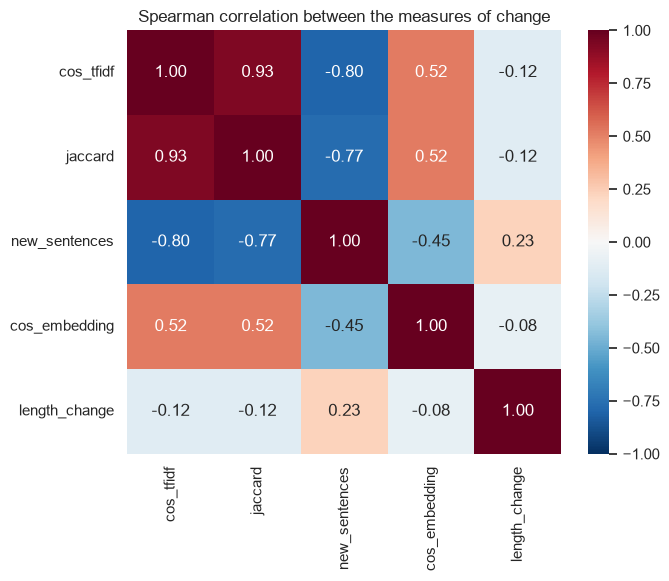

In [6]:
plt.figure(figsize=(7, 5.5))
sns.heatmap(pares[medidas].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Spearman correlation between the measures of change")
plt.savefig("figures/measures_correlation.png", bbox_inches="tight")
plt.show()

The measures agree a lot (the share of new sentences moves against the similarities, as expected). A typical company keeps most of its risk factors: the median share of new sentences shows how much of the text is rewritten each year.

Which reports changed the most?

In [7]:
pares["year"] = pares["filing_date"].dt.year
pares.sort_values("cos_tfidf")[["ticker", "name", "filing_date", "words", "cos_tfidf", "new_sentences", "cos_embedding"]].head(10).round(3)

,ticker,name,filing_date,words,cos_tfidf,new_sentences,cos_embedding
535,LIN,LINDE PLC,2019-03-18,4250,0.334,0.967,0.969
1001,V,VISA INC.,2016-11-15,7399,0.412,0.914,0.991
904,T,AT&T INC.,2020-02-20,4939,0.417,0.993,0.987
1035,VRTX,VERTEX PHARMACEUTICALS INC / MA,2026-02-13,10503,0.419,0.898,0.991
1018,VLO,VALERO ENERGY CORP/TX,2022-02-22,16624,0.478,0.877,0.987
965,TXN,TEXAS INSTRUMENTS INC,2020-02-20,1183,0.517,0.381,0.988
499,JPM,JPMORGAN CHASE & CO,2018-02-27,13989,0.522,0.972,0.978
843,RTX,RTX Corp,2021-02-08,13517,0.523,0.804,0.992
873,SPGI,S&P Global Inc.,2015-02-13,5061,0.538,0.930,0.992
966,TXN,TEXAS INSTRUMENTS INC,2021-02-05,3841,0.542,0.807,0.990


      cos_tfidf  new_sentences  cos_embedding
year                                         
2015      0.908          0.336          0.994
2016      0.908          0.343          0.994
2017      0.900          0.333          0.994
2018      0.907          0.350          0.994
2019      0.903          0.331          0.995
2020      0.890          0.381          0.994
2021      0.859          0.464          0.993
2022      0.898          0.381          0.994
2023      0.899          0.346          0.994
2024      0.895          0.347          0.994
2025      0.921          0.341          0.994
2026      0.918          0.327          0.994


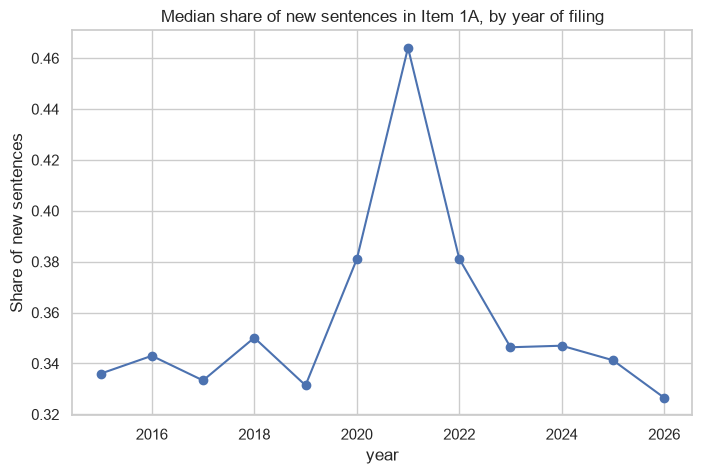

In [8]:
print(pares.groupby("year")[["cos_tfidf", "new_sentences", "cos_embedding"]].median().round(3))
plt.figure(figsize=(8, 5))
pares.groupby("year")["new_sentences"].median().plot(marker="o")
plt.title("Median share of new sentences in Item 1A, by year of filing")
plt.ylabel("Share of new sentences")
plt.savefig("figures/new_sentences_by_year.png", bbox_inches="tight")
plt.show()

## Part 4. What changed: topics in the risk factors

Share of reports of each year that mention some topics at least once (simple keyword search).

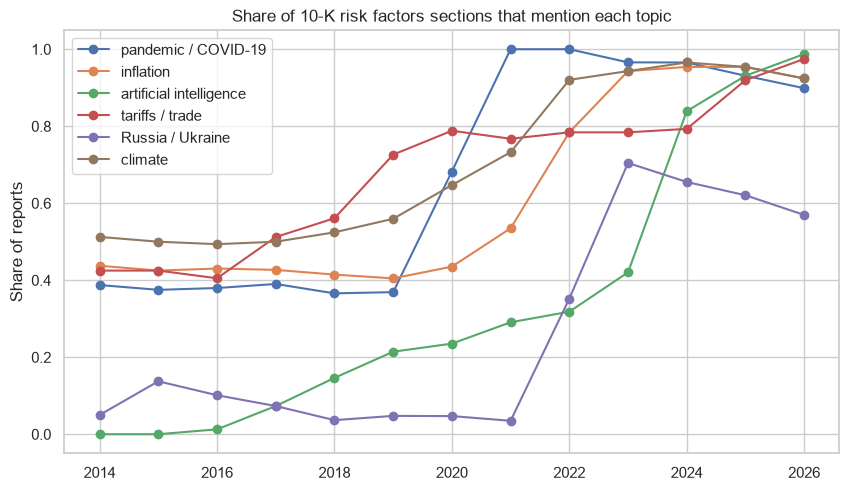

,pandemic / COVID-19,inflation,artificial intelligence,tariffs / trade,cybersecurity,climate,Russia / Ukraine,interest rates
filing_date,,,,,,,,
2014,0.39,0.44,0.00,0.42,0.64,0.51,0.05,0.72
2015,0.38,0.42,0.00,0.42,0.78,0.50,0.14,0.70
2016,0.38,0.43,0.01,0.41,0.81,0.49,0.10,0.71
2017,0.39,0.43,0.07,0.51,0.85,0.50,0.07,0.71
2018,0.37,0.41,0.15,0.56,0.89,0.52,0.04,0.71
2019,0.37,0.40,0.21,0.73,0.90,0.56,0.05,0.74
2020,0.68,0.44,0.24,0.79,0.95,0.65,0.05,0.73
2021,1.00,0.53,0.29,0.77,0.99,0.73,0.03,0.80
2022,1.00,0.78,0.32,0.78,0.99,0.92,0.35,0.85


In [9]:
temas = {"pandemic / COVID-19": r"covid|pandemic", "inflation": r"inflation", "artificial intelligence": r"artificial intelligence|generative ai|\bai\b",
         "tariffs / trade": r"tariff", "cybersecurity": r"cyber", "climate": r"climate", "Russia / Ukraine": r"ukraine", "interest rates": r"interest rate"}
anios = rep["filing_date"].dt.year
tabla = pd.DataFrame({tema: rep["text"].str.lower().str.contains(p).groupby(anios).mean() for tema, p in temas.items()})
cuantos = anios.value_counts()
tabla = tabla[tabla.index.isin(cuantos[cuantos >= 30].index)]          # years with at least 30 reports

plt.figure(figsize=(10, 5.5))
for c in ["pandemic / COVID-19", "inflation", "artificial intelligence", "tariffs / trade", "Russia / Ukraine", "climate"]:
    plt.plot(tabla.index, tabla[c], marker="o", label=c)
plt.title("Share of 10-K risk factors sections that mention each topic")
plt.ylabel("Share of reports")
plt.legend()
plt.savefig("figures/topics_over_time.png", bbox_inches="tight")
plt.show()
tabla.round(2)

The risk factors follow the news:

- **Pandemic:** around 38% of the reports already mentioned a pandemic before 2020, as a generic risk; it was in all of them in 2021 and 2022.
- **Inflation:** from about 42% of the reports to 94% in 2023.
- **Russia / Ukraine:** from 3-5% to 70% in 2023.
- **Artificial intelligence:** the biggest change. It was in no report in 2014, in 42% in 2023 and in 99% in 2026.
- **Tariffs:** they go up with the trade war of 2018-2019 (from 42% to 73%) and again in 2025-2026, to 97%.

## Part 5. Returns after the filing

Excess return of the stock against SPY (the S&P 500) from the second trading day after the filing to 5, 63, 126 and 252 trading days (1 week, 3, 6 and 12 months). If prices are "lazy", companies that changed their risk factors a lot (low similarity) should have lower excess returns later, not in the first week.

In [10]:
precios = pd.read_parquet("data/prices.parquet")
lp = np.log(precios)

def exceso(tk, fecha, h):
    if tk not in lp.columns:
        return np.nan
    pos = lp.index.searchsorted(fecha) + 1
    if pos + h >= len(lp):
        return np.nan
    r = lp[tk].iloc[pos + h] - lp[tk].iloc[pos]
    m = lp["SPY"].iloc[pos + h] - lp["SPY"].iloc[pos]
    return r - m

for h, nombre in [(5, "ret_1w"), (63, "ret_3m"), (126, "ret_6m"), (252, "ret_12m")]:
    pares[nombre] = [exceso(t, f, h) for t, f in zip(pares["ticker"], pares["filing_date"])]
pares[["ret_1w", "ret_3m", "ret_6m", "ret_12m"]].describe().round(3)

,ret_1w,ret_3m,ret_6m,ret_12m
count,979.000,969.000,968.000,894.000
mean,0.000,0.006,0.019,0.046
std,0.040,0.145,0.196,0.271
min,-0.225,-0.743,-0.685,-0.766
25%,-0.016,-0.073,-0.091,-0.108
50%,0.001,0.004,0.015,0.030
75%,0.019,0.082,0.106,0.176
max,0.169,1.059,1.268,1.704


Each year we sort the reports in quintiles by TF-IDF similarity (quintile 1 = the ones that changed the most). Ranking inside each year removes the effect of years where everybody changed (2020).

          ret_1w  ret_3m  ret_6m  ret_12m    n
quintile                                      
1           0.49    2.51    3.22     4.43  203
2          -0.05    0.37    1.15     4.27  195
3           0.29    0.98    2.92     5.79  197
4           0.15   -0.41    2.07     5.03  195
5          -0.69   -0.55   -0.14     3.28  202
Quintile 5 (non-changers) minus quintile 1 (changers), 12 months: -1.15 %


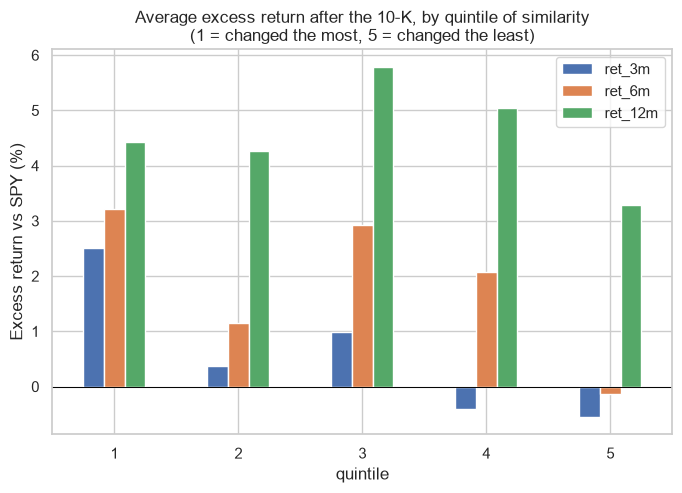

In [11]:
pares["quintile"] = pares.groupby("year")["cos_tfidf"].transform(lambda s: pd.qcut(s.rank(method="first"), 5, labels=False) + 1)
q = pares.groupby("quintile")[["ret_1w", "ret_3m", "ret_6m", "ret_12m"]].mean() * 100
q["n"] = pares.groupby("quintile").size()
print(q.round(2))
print("Quintile 5 (non-changers) minus quintile 1 (changers), 12 months:", round(q.loc[5, "ret_12m"] - q.loc[1, "ret_12m"], 2), "%")

plt.figure(figsize=(8, 5))
q[["ret_3m", "ret_6m", "ret_12m"]].plot.bar(ax=plt.gca())
plt.axhline(0, color="black", lw=0.7)
plt.title("Average excess return after the 10-K, by quintile of similarity\n(1 = changed the most, 5 = changed the least)")
plt.ylabel("Excess return vs SPY (%)")
plt.xticks(rotation=0)
plt.savefig("figures/returns_by_quintile.png", bbox_inches="tight")
plt.show()

A regression with all the measures (standardised, so the coefficients are comparable), year fixed effects and errors clustered by company. A positive coefficient for a similarity means "the more similar, the better the future return", which is the lazy prices hypothesis. We use the reports that have returns at all the horizons (the last year of filings has no 12-month return yet), so the four horizons have the same sample.

In [12]:
z = pares.dropna(subset=["ret_12m"]).copy()
for c in medidas:
    z[c + "_z"] = (z[c] - z[c].mean()) / z[c].std()
z["cluster"] = z["ticker"].astype("category").cat.codes

filas = []
for medida in ["cos_tfidf", "jaccard", "new_sentences", "cos_embedding"]:
    for y in ["ret_1w", "ret_3m", "ret_6m", "ret_12m"]:
        m = smf.ols(f"{y} ~ {medida}_z + length_change_z + C(year)", z.dropna(subset=[y])).fit(cov_type="cluster", cov_kwds={"groups": z.dropna(subset=[y])["cluster"]})
        filas.append({"measure": medida, "horizon": y, "coef_pct": m.params[f"{medida}_z"] * 100, "t": m.tvalues[f"{medida}_z"], "p": m.pvalues[f"{medida}_z"], "n": int(m.nobs)})
reg = pd.DataFrame(filas)
reg.pivot(index="measure", columns="horizon", values="t").round(2)

horizon,ret_12m,ret_1w,ret_3m,ret_6m
measure,,,,
cos_embedding,0.00,-0.42,-2.09,-1.07
cos_tfidf,-0.21,-2.20,-1.68,-0.62
jaccard,0.18,-2.75,-1.70,-0.36
new_sentences,0.52,1.71,2.12,0.78


In [13]:
reg.round(3)

,measure,horizon,coef_pct,t,p,n
0,cos_tfidf,ret_1w,-0.244,-2.196,0.028,894
1,cos_tfidf,ret_3m,-0.687,-1.683,0.092,894
2,cos_tfidf,ret_6m,-0.351,-0.619,0.536,894
3,cos_tfidf,ret_12m,-0.167,-0.215,0.830,894
4,jaccard,ret_1w,-0.344,-2.753,0.006,894
5,jaccard,ret_3m,-0.672,-1.697,0.090,894
6,jaccard,ret_6m,-0.190,-0.356,0.722,894
7,jaccard,ret_12m,0.137,0.180,0.857,894
8,new_sentences,ret_1w,0.222,1.713,0.087,894
9,new_sentences,ret_3m,0.739,2.119,0.034,894


## Part 6. A bootstrap of the long-short portfolio

The sample is small (76 companies), so we check how uncertain the 12-month spread between non-changers and changers is, resampling companies (to keep the dependence between the reports of the same company).

In [14]:
np.random.seed(0)
empresas = z["ticker"].unique()
boot = []
for _ in range(2000):
    muestra = pd.concat([z[z["ticker"] == t] for t in np.random.choice(empresas, len(empresas))])
    g = muestra.groupby("quintile")["ret_12m"].mean()
    if 1 in g and 5 in g:
        boot.append(g[5] - g[1])
print("Spread Q5 - Q1 at 12 months:", round((z.groupby("quintile")["ret_12m"].mean()[5] - z.groupby("quintile")["ret_12m"].mean()[1]) * 100, 2), "%")
print("95% bootstrap interval:", np.round(np.percentile(boot, [2.5, 97.5]) * 100, 2), "%")

Spread Q5 - Q1 at 12 months: -1.15 %
95% bootstrap interval: [-6.37  3.92] %


## Conclusions

- **The text of the risk factors changes every year, and it follows the news.** About a third of the sentences of a typical report are new each year (46% in the 2021 reports, after the pandemic), and the section grew 70% in length from 2014 to 2026. Artificial intelligence went from no report to 99% of them.
- **No lazy prices in this sample.** Sorting the reports by how much they changed, the 12-month excess return of the non-changers minus the changers is -1.2%, with a bootstrap interval from -6.4% to +3.9%. None of the four measures predicts the 6 or 12 month return.
- **If anything, the changers did a little better in the short run,** the opposite sign of the paper: at 1 week and 3 months some coefficients have t-statistics around 2. With 4 measures and 4 horizons, a few t-statistics of 2 are expected by chance, so this is weak evidence.
- **Why not like the paper?** The paper used all US firms from 1995 to 2014, small ones included; here there are only 92 mega caps, very followed by analysts, from 2015 to 2026, after the paper was published (2020) and the signal could be traded away.
- **On the method:** the average embedding of a long section hardly moves (cosine 0.994 on average): averaging hides the change. Measures at the level of words or sentences show much better what changed.